# Queueing Theory

Moreno Marzolla

Last modified on 2026-10-22

---



1 0 3.0 1.0
2 0 4.0 2.0
2 1 6.0 1.0
3 1 7.0 2.0
3 2 8.0 1.0
3 3 9.0 0.0
4 3 12.0 1.0
5 3 13.0 2.0
5 4 15.0 1.0
5 5 19.0 0.0
6 5 21.0 1.0
7 5 22.0 2.0
8 5 24.0 3.0
8 6 25.0 2.0
9 6 26.0 3.0
9 7 27.0 2.0
9 8 32.0 1.0
9 9 33.0 0.0
1.4


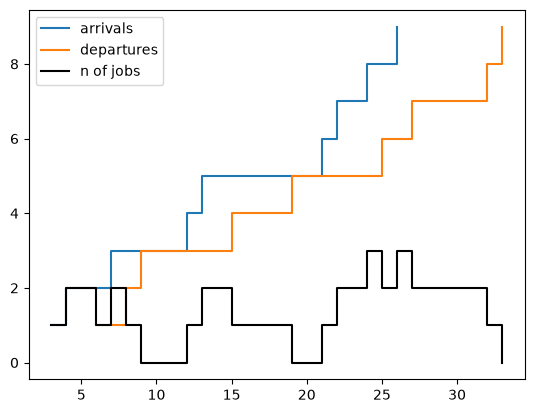

In [1]:
import numpy as np
import matplotlib.pyplot as plt

arrivals = np.array([3, 4, 7, 12, 13, 21, 22, 24, 26]) # arrival times
services = np.array([3, 2, 1,  3,  4,  4,  2,  5,  1]) # service times
departures = np.zeros_like(arrivals) # departure times

departures[0] = arrivals[0] + services[0]
# computation of departure times
for i in range(1,len(arrivals)):
    if departures[i-1] < arrivals[i]:
        departures[i] = arrivals[i] + services[i]
    else:
        departures[i] = departures[i-1] + services[i]

# computation of number of jobs in the system
tt = np.zeros(2 * len(arrivals))
njobs = np.zeros_like(tt)
i = j = 0
nj = 0
for k in range(0, len(tt)):
    if (i < len(arrivals)) and ((j >= len(departures)) or (arrivals[i] <= departures[j])):
        tt[k] = arrivals[i]
        i = i+1
        nj = nj+1
    else:
        tt[k] = departures[j]
        j = j+1
        nj = nj-1
    njobs[k] = nj
    print(i,j,tt[k], njobs[k])

Q = np.sum(departures-arrivals) / (np.max(departures) - np.min(arrivals))
print(Q)
iota = np.arange(1, 1+len(arrivals)) # the array (1, 2, ... n)

plt.step(arrivals, iota, where='post', label="arrivals")
plt.step(departures, iota, where='post', label="departures")
plt.step(tt, njobs, c='black', where='post', label="n of jobs")
plt.legend()
plt.show()